<a href="https://colab.research.google.com/github/ashsiendo/DATA-201-Project1/blob/main/Project_1_Bank_Marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project 1** - Ash Ibasan

The focus of this project is classification using the bank marketing dataset. I will compare logistic regression, LDA, QDA, and KNN to predict whether a customer will subscribe to a term deposit.

I will also consider the trade-off between contacting customers unlikely to subscribe and missing customers who would have subscribed, rather than focusing solely on accuracy.

> ***Note to self: Comments throughout are used as guides, mainly for Python syntax and reasons why certain steps are used.***

## **Setup**
*Import libraries needed for the project and load the bank marketing dataset*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
bank = pd.read_csv("https://raw.githubusercontent.com/ashsiendo/DATA-201-Project1/refs/heads/main/bank-full.csv", sep=";") # sep=";" tells pandas that columns are separated by semicolons

## **Part 1 - What am I trying to predict?**
*Identify what the data represents, what I am predicting, and the consequences of incorrect predictions*

In [3]:
bank.shape # 45,211 observations, 17 columns

(45211, 17)

In [4]:
bank["y"].value_counts()

,count
y,
no,39922
yes,5289


**`y` has two classes: `yes` = subscribed, and `no` = did not subscribe**

In [5]:
bank["y"].value_counts(normalize=True) * 100 # proportions converted to percentages

,proportion
y,
no,88.30152
yes,11.69848


The dataset contains 45,211 observations and 17 columns, including `y`, the response variable. Each row contains recorded client characteristics, campaign information, and whether the client subscribed to the term deposit. `y` has two classes: `yes` and `no`; I will treat `yes` as the positive class.

About 88.3% of observations are `no` and 11.7% are `yes`; therefore, the response is imbalanced, and accuracy alone could be misleading. A model that predicts `no` for every customer would already be about 88.3% accurate, but would fail to identify any actual subscribers.

In [6]:
majority_class = bank["y"].value_counts().idxmax() # majority-class baseline
baseline_accuracy = bank["y"].value_counts(normalize=True).max()

print("Majority class:", majority_class)
print("Baseline accuracy:", round(baseline_accuracy, 4)) # round to four decimal places

Majority class: no
Baseline accuracy: 0.883


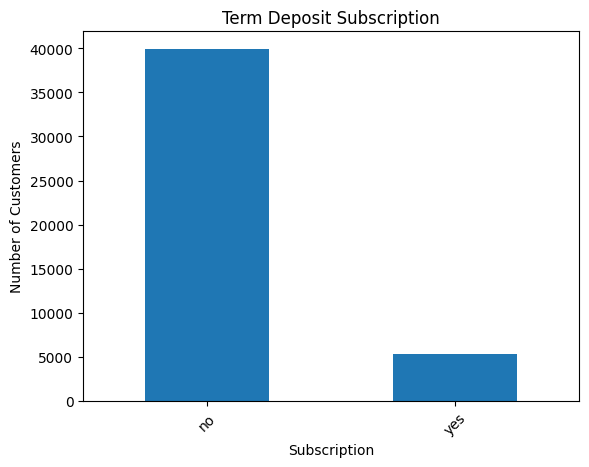

In [7]:
bank["y"].value_counts().plot(kind="bar")

plt.title("Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45) # rotates x-axis labels 45 degrees
plt.show()

The bar chart confirms the class imbalance, with the `no` class much larger than the `yes` class.

### Prediction scenario

**The model will be framed as a pre-contact targeting tool:**
> *Before contacting a customer, can the bank identify customers who are more likely to subscribe to a term deposit?*

I only want to use information the bank would already know at that point because the prediction happens before the customer is contacted; for example, `duration` records how long the current contact lasted, so it would not be available yet and will be excluded.

### Predictor selection

I will focus on variables that could realistically be known before contact, such as customer characteristics, financial information, and previous campaign history.

I will then explore the predictors more closely later on before deciding on the final set. The main aspects I will consider are whether the variable is available before contact, the data are usable, and if the variable seems relevant to predicting subscription.

### False positives, false negatives, trade-offs

Keep in mind, `yes` is the positive class.

A **false positive** occurs when the model predicts that a customer will subscribe, but they don't. The bank may spend time and resources contacting someone unlikely to subscribe.

A **false negative** happens when the model predicts that a customer will not subscribe, but they did. If the bank relies on this prediction to choose whom to contact, it might miss out on a potential subscriber.

Both types of errors are important, but I will focus on reducing false negatives first since the main goal is to find potential subscribers. Reaching out to more customers might also lead to more false positives, so I will keep both missed opportunities and unnecessary outreach in mind when comparing models. The dataset does not include the exact costs of these errors.

## **Part 2 - What does the data look like, and how will I prepare it?**
*Inspect the predictors, variable types, and data quality, then prepare the data for modeling*

In [8]:
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [9]:
bank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


### Missing information and data quality
*Check missing values, unknown categories, and repeated rows before deciding how to handle them*

In [10]:
bank.isna().sum()  # count pandas missing values in each column

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [11]:
(bank == "unknown").sum() # count literal "unknown" entries; these are not NaNs

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day,0


In [12]:
bank.duplicated().sum() # count rows that are exact duplicates

np.int64(0)

`pandas` does not identify any missing values, and there are no exact duplicate rows, although `"unknown"` appears in the `job` category (288 times), `education` (1,857 times), `contact` (13,020 times), and `poutcome` (36,959 times).

The information in these categories is unknown or not available, and therefore the absence of `NaN` values doesn't imply all the values are known; I will look into what these values mean before determining how to deal with them.

In [13]:
bank["pdays"].value_counts().head(10) # show 10 most frequent values

,count
pdays,
-1,36954
182,167
92,147
183,126
91,126
181,117
370,99
184,85
364,77


`-1` in `pdays` means the client was not previously contacted in a previous campaign; `-1` is considered as a special code rather than an actual number of days. Treating it as an ordinary day count could mislead a distance-based model such as KNN.

In [14]:
pd.crosstab(bank["pdays"] == -1, bank["poutcome"]) # True means pdays = -1; compare this group with previous campaign outcomes

poutcome,failure,other,success,unknown
pdays,,,,
False,4901,1840,1511,5
True,0,0,0,36954


There are `36,954` cases where `pdays` is -1, and all of these have an `"unknown"` outcome from the previous campaign. Only five cases with a different `pdays` value have an unknown outcome.

The fact that this is the case suggests that the vast majority of previous outcomes that are `"unknown"` probably reflect no earlier campaign contact, since most of those observations also have `pdays = -1`; therefore, I'll include these cases and regard `"unknown"` as a separate category in `poutcome`.


### Numerical summary
*Examine the ranges and spread of numeric variables, keeping special codes and prediction timing in mind*

In [15]:
bank.describe().T  # transpose so each variable is a row

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


The numeric variables vary a lot in their ranges. For example, the mean `balance` is much higher than the median, and some values are very large, suggesting a right skew. The counts for `campaign` and `previous` contacts also have values well above their upper quartiles.

These extreme values should be checked, but I won't remove them just because they are large. The summary for `pdays` also uses the special code `-1`, so the mean doesn't only reflect clients who had previous contact.

***Note to self:*** scaling is important for KNN because variables with larger ranges can have a bigger impact on distance calculations. However, scaling does not solve skewness or deal with special codes.


In [16]:
bank.nlargest(5, "previous")[["previous", "pdays", "poutcome", "campaign"]] # inspect five largest previous-contact counts alongside campaign history

,previous,pdays,poutcome,campaign
29182,275,262,other,2
38326,58,353,other,2
44089,55,776,failure,3
28886,51,256,failure,3
44822,41,778,other,1


The highest `previous`-contact count is 275, while the next highest is 58. This value stands out as unusually high, but I don't have enough evidence to call it an error. For now, I'll keep it and take its possible impact into account during modeling.

In [17]:
bank.describe(include="object").T # summarize categorical columns, categories, and most common values

,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


The categorical predictors include binary variables like `housing` and `loan`, as well as variables with several categories, such as `job` and `education`. These categories need to be converted into numbers before modeling.

***Note to self:*** Assigning random numbers to categories like `job` might suggest an order or distance that is not really there. One-hot encoding can solve this by using separate columns for each category. The response variable `y` will be managed separately from the predictors.

### Initial predictor set
*Select client characteristics, financial information, and previous campaign history that could be available before contact*

At first, I will leave out `duration`, `contact`, `day`, `month`, and `campaign`. These features describe the current campaign’s contact activity, and including them would mean making more assumptions about what is known at prediction time. I will also leave out `pdays` for now, since its `-1` code needs to be handled separately. The features `previous` and `poutcome` will still give information about previous campaigns, but by excluding `pdays`, we lose details about how recently a client was last contacted.

I'll continue to use `"unknown"` as a category at this stage than to be treated as a missing value.

In [18]:
predictors = [ # predictors kept for pre-contact model
    "age", "job", "marital", "education",
    "default", "balance", "housing", "loan",
    "previous", "poutcome"
]

X = bank[predictors] # features used to make predictions
y = bank["y"] # response: whether the customer subscribed

X.shape

(45211, 10)

In [19]:
print(X.shape[1]) # check number, names of my selected predictors
print(X.columns.tolist())

10
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'previous', 'poutcome']


### Training and test sets
*Reserve 25% of the data for final testing and use the remaining 75% for training and cross-validation*

I'll use the same data split for all four models, and stratification helps make sure that the subscription classes are represented in similar proportions in both sets.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=12, # makes the split reproducible
    stratify=y # preserves approximate class proportions
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (33908, 10)
Testing: (11303, 10)


### Encoding and standardization
*Convert categorical predictors into numbers and standardize numeric predictors as part of the modeling pipeline*

Categorical predictors need to be converted to numbers. For all four models, I will use the same preprocessing steps: one-hot encoding for categorical predictors and standardizing numeric predictors. Scaling is especially important for KNN since bigger numbers can skew distance calculations. I will fit the preprocessing within each cross-validation training fold.

In [21]:
num_features = ["age", "balance", "previous"]

cat_features = [
    "job", "marital", "education",
    "default", "housing", "loan", "poutcome"
]

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# define steps here; fitting happens later inside the model pipelines

preprocessor = ColumnTransformer( # apply different preprocessing to numeric and categorical columns; each tuple contains step name, transformer, columns
    transformers=[
        ("numeric", StandardScaler(), num_features),
        ("categorical", OneHotEncoder(
            drop="first", # leave one category out as reference
            handle_unknown="ignore", # unseen categories become all zeroes for that feature
            sparse_output=False # return regular array
        ), cat_features)
    ]
)

### Cross-validation setup
*To test all four classifiers, divide the training data into five stratified folds*




The different subscription classes are maintained in roughly the same proportions in each fold, and I'll use the same folds for each model so that the comparisons remain consistent.

***Note to self:*** the pipeline should carry out encoding and scaling only on the training portion of each fold, and the test set should be kept for the final evaluation.

In [23]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=12
)

## **Part 3 - Building and comparing the classifiers**
*Take the training data and apply 5-fold cross-validation to compare logistic regression, LDA, QDA, and KNN. Make sure the same preprocessing steps, folds, and scoring metric are used for all models*

Since the response is imbalanced, I will use ROC-AUC as the main cross-validation metric instead of accuracy. ROC-AUC shows how well a model ranks positive and negative classes at different thresholds.

For all four models, I will employ the same 5-fold stratified cross-validation procedure and preprocessing and KNN tuning use only training data, while the held-out test results support my final comparison and recommendation.

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.neighbors import KNeighborsClassifier

### Logistic Regression
*The first model to be evaluated is logistic regression; the same predictors, the same preprocessing steps, 5-fold cross-validation, and ROC-AUC scoring will be used*

In [25]:
# build pipeline so preprocessing happens inside each CV training fold
lr_model = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000) # max_iter gives model more chances to converge if default limit is not enough
)

# evaluate LR using only training data
lr_cv = cross_val_score(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("LR CV AUC scores:", lr_cv.round(4))
print("LR average CV AUC:", round(lr_cv.mean(), 4))

LR CV AUC scores: [0.707  0.7145 0.7151 0.7019 0.7113]
LR average CV AUC: 0.7099


### LDA
*LDA will use the same predictors, preprocessing method, CV folds, and ROC-AUC scoring as LR so the two models can be compared consistently*

In [26]:
lda_model = make_pipeline( # use same preprocessing and folds as LR
    preprocessor,
    LinearDiscriminantAnalysis()
)

lda_cv = cross_val_score(
    lda_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("LDA CV AUC scores:", lda_cv.round(4))
print("LDA average CV AUC:", round(lda_cv.mean(), 4))

LDA CV AUC scores: [0.7065 0.7137 0.7142 0.7007 0.7097]
LDA average CV AUC: 0.709


### QDA
*To ensure a consistent comparison with LR and LDA, QDA will use the same predictors, preprocessing steps, CV folds, and ROC-AUC scoring*

In [27]:
qda_model = make_pipeline( # QDA estimates separate covariance matrix for each class
    preprocessor,
    QuadraticDiscriminantAnalysis()
)

qda_cv = cross_val_score(
    qda_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("QDA CV AUC scores:", qda_cv.round(4))
print("QDA average CV AUC:", round(qda_cv.mean(), 4))

QDA CV AUC scores: [0.697  0.6918 0.6714 0.6833 0.6971]
QDA average CV AUC: 0.6881


QDA achieved an average cross-validation AUC of `0.6881`, lower than LR's `0.7099`, but the added flexibility in QDA’s decision boundary didn't improve ranking performance with these predictors.

### KNN
*KNN differs from the other classifiers because it requires choosing the number of neighbors, $ k $. I will test several $ k $ values, using the same training data, 5-fold cross-validation, and ROC-AUC scoring*

In [28]:
from sklearn.model_selection import GridSearchCV

knn_model = make_pipeline( # build KNN pipeline so preprocessing happens inside each CV fold
    preprocessor,
    KNeighborsClassifier()
)

knn_grid = {
    "kneighborsclassifier__n_neighbors": [1, 3, 5, 11, 21, 51, 75, 101, 151, 201, 301, 501, 751, 1001],
    "kneighborsclassifier__weights": ["uniform", "distance"]
}

knn_search = GridSearchCV( # tune KNN using same CV folds and ROC-AUC metric
    knn_model,
    knn_grid,
    cv=cv,
    scoring="roc_auc"
)

knn_search.fit(X_train, y_train) # run grid search using only training data; test data stays untouched

print("Best k:", knn_search.best_params_["kneighborsclassifier__n_neighbors"])
print("Best weights:", knn_search.best_params_["kneighborsclassifier__weights"])
print("KNN best average CV AUC:", round(knn_search.best_score_, 4))

Best k: 501
Best weights: uniform
KNN best average CV AUC: 0.7104


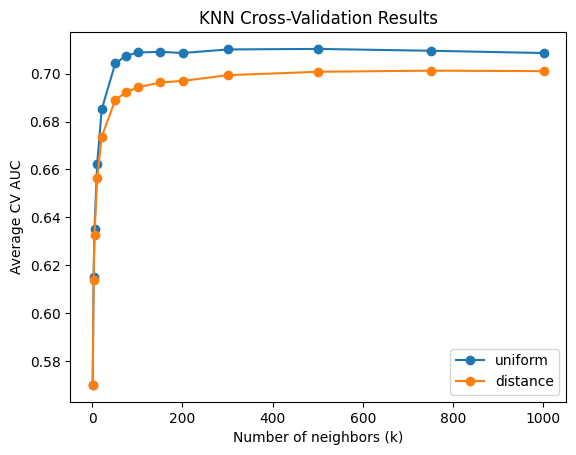

In [29]:
knn_results = pd.DataFrame(knn_search.cv_results_)

for weight in ["uniform", "distance"]: # plot each voting method separately in order of k
    results = knn_results[
        knn_results["param_kneighborsclassifier__weights"] == weight
    ].sort_values("param_kneighborsclassifier__n_neighbors")

    plt.plot(
        results["param_kneighborsclassifier__n_neighbors"].astype(int),
        results["mean_test_score"],
        marker="o",
        label=weight
    )

plt.xlabel("Number of neighbors (k)")
plt.ylabel("Average CV AUC")
plt.title("KNN Cross-Validation Results")
plt.legend()
plt.show()

I expanded the range of $ k $ since the highest value at first yielded the best results. When I tested selected values up to 1001, $ k=501 $ gave the highest average CV AUC (`0.7104`), so I decided to use it in the final evaluation.

### Final model fitting and test predictions

In [30]:
# fit three untuned models on full training set
lr_model.fit(X_train, y_train)
lda_model.fit(X_train, y_train)
qda_model.fit(X_train, y_train)

knn_final = knn_search.best_estimator_ # GridSearchCV already refit best KNN model on all training data

print("Class order:", lr_model.classes_) # check class order (no/yes) before selecting positive-class probability

Class order: ['no' 'yes']


In [31]:
# predicted class labels for test set
lr_pred = lr_model.predict(X_test)
lda_pred = lda_model.predict(X_test)
qda_pred = qda_model.predict(X_test)
knn_pred = knn_final.predict(X_test)

# predicted probabilities for positive class ("yes")
lr_prob = lr_model.predict_proba(X_test)[:, 1]
lda_prob = lda_model.predict_proba(X_test)[:, 1]
qda_prob = qda_model.predict_proba(X_test)[:, 1]
knn_prob = knn_final.predict_proba(X_test)[:, 1]

In [32]:
pd.DataFrame({ # show sample of LR test predictions, probabilities
    "Actual": y_test,
    "LR prediction": lr_pred,
    "LR probability of yes": lr_prob
}).head(10)

,Actual,LR prediction,LR probability of yes
39996,yes,no,0.180414
14905,yes,no,0.050876
22277,no,no,0.171914
2678,no,no,0.117665
23535,no,no,0.086358
28296,no,no,0.107452
39037,no,no,0.026851
1060,no,no,0.050434
9749,no,no,0.088795
13894,no,no,0.088515


## **Part 4 - How do the models perform on the test set?**
*I will compare all four models on the same held-out test set, using their default 0.50 probability cutoff. This way, we have a consistent starting point to look at missed subscribers and unnecessary outreach*

### Confusion matrices and evaluation metrics

In [33]:
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

In [34]:
# rows = actual class; columns = predicted class
# keep same class order, arranged as TN, FP/FN, TP, for all matrices: no, then yes
lr_cm = confusion_matrix(y_test, lr_pred, labels=["no", "yes"])
lda_cm = confusion_matrix(y_test, lda_pred, labels=["no", "yes"])
qda_cm = confusion_matrix(y_test, qda_pred, labels=["no", "yes"])
knn_cm = confusion_matrix(y_test, knn_pred, labels=["no", "yes"])

print("LR:\n", lr_cm)
print("\nLDA:\n", lda_cm)
print("\nQDA:\n", qda_cm)
print("\nKNN:\n", knn_cm)

# \n: new line

LR:
 [[9877  104]
 [1111  211]]

LDA:
 [[9849  132]
 [1078  244]]

QDA:
 [[8865 1116]
 [ 845  477]]

KNN:
 [[9981    0]
 [1322    0]]


In [35]:
def evaluate_model(pred, prob, cm): # calculate same evaluation metrics for each classifier
    tn, fp, fn, tp = cm.ravel() # unpack matrix into its four counts

    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, pos_label="yes", zero_division=0
        ),
        "Recall": recall_score(y_test, pred, pos_label="yes"),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_test, pred, pos_label="yes"),
        "ROC-AUC": roc_auc_score(y_test == "yes", prob)
    }

metrics = pd.DataFrame({
    "LR": evaluate_model(lr_pred, lr_prob, lr_cm),
    "LDA": evaluate_model(lda_pred, lda_prob, lda_cm),
    "QDA": evaluate_model(qda_pred, qda_prob, qda_cm),
    "KNN": evaluate_model(knn_pred, knn_prob, knn_cm)
}).T

metrics.round(4)

,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
LR,0.8925,0.6698,0.1596,0.9896,0.2578,0.7247
LDA,0.8929,0.6489,0.1846,0.9868,0.2874,0.7241
QDA,0.8265,0.2994,0.3608,0.8882,0.3273,0.6912
KNN,0.8830,0.0000,0.0000,1.0000,0.0000,0.7273


I used a default threshold of 0.50 as a standard basis for comparing all four models. The threshold was not set with reference to business requirements because I did not know the bank's outreach costs or objectives. Additionally, I did not select a different cutoff on the basis of the test set.

Logistic regression and LDA gave almost the same results. Both had high accuracy and specificity but low recall, so they found most non-subscribers but missed many real subscribers. LDA found a few more correctly identified actual subscribers than LR, but it also made a few more false positive errors.

Although QDA had lower accuracy and specificity, it achieved the highest recall and F1 score; it identified more genuine subscribers, but at the cost of a large number of false positives and having to carry out additional outreach.

Despite KNN having the highest ROC-AUC (`0.7273`), at a threshold of `0.50`, it predicted all of the test observations as "no", resulting in a recall and an F1 score of zero. Precision could not be determined mathematically since no positive predictions were made, but the code showed it as 0 because I had set `zero_division=0`. The AUC indicates that the probability rankings still had some useful information, even though its classifications at this cutoff did not achieve my objective of identifying potential subscribers.

The always-"no" baseline accuracy was about 88.3%, the same as KNN’s accuracy, showing why accuracy on its own can be misleading: a model can correctly classify most observations while identifying none of the actual subscribers.

## **Part 5 - What do these numbers tell me?**

### What are the most important metrics?

The first thing I want to prioritize is recall to identify more potential subscribers in order to cut down on missed opportunities. At the same time, precision is important since it takes up time and resources to contact people. Specificity is also helpful as it demonstrates how well the models avoid flagging actual non-subscribers for contact.
F1 and ROC-AUC offer further insights: F1 gives an overview of the balance between precision and recall, whereas ROC-AUC illustrates how well the models are able to rank subscribers higher than non-subscribers at various classification thresholds. QDA achieved the highest F1 score at the 0.50 cutoff (0.3273), and KNN obtained the highest AUC. Yet neither of these measures by itself identifies the most useful model or takes into account the bank's real business costs.

### Understanding false positives, false negatives

False positives might result in unwanted contacts with customers who do not subscribe, while false negatives would mean failing to identify potential subscribers. Although I place greater importance on avoiding missed opportunities, it doesn't mean I'm willing to accept unlimited unnecessary contact. Yet without knowing the cost of making contacts, the value of a subscription, and the capacity of the campaign, I'm unable to decide which compromise would be the most profitable.

### Balancing model trade-offs

At the 0.50 cutoff, both LR and LDA were selective but missed many real subscribers. LDA found 33 more subscribers than LR, but also had 28 more false positives. I think this trade-off is worthwhile based on my priorities, but the bank needs to decide if the extra cost is justified.
QDA identified 477 actual subscribers but also generated 1,116 false positives, and even with the highest recall, it still failed to pick up about 64% of the actual subscribers. Although KNN achieved the highest AUC, it detected no subscribers at this cutoff. The results indicate that identifying more actual subscribers, reducing unnecessary outreach, and properly ranking customers are three separate issues.

### Why accuracy alone can be misleading

Since about 88% of customers did not subscribe, simply predicting "no" for everyone already gives high accuracy. KNN had a test accuracy of about 88.3%, matching the always-"no" baseline, but its recall was zero. It also found all the non-subscribers but missed every actual subscriber. If I only looked at accuracy, I would have missed this problem.

## **Part 6 - ROC and AUC**
*ROC curves help us see how well the models can tell subscribers apart from non-subscribers across different classification thresholds. Unlike the confusion matrix metrics in Part 4, ROC-AUC uses the predicted probabilities instead of only the final class predictions*

### ROC Curves

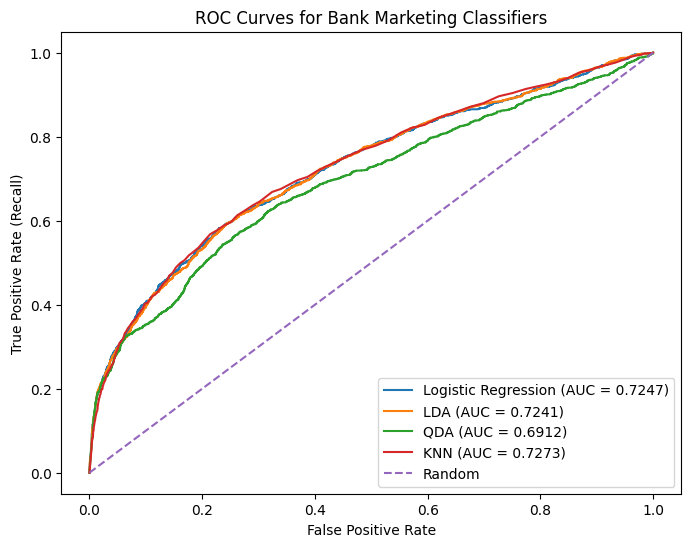

In [36]:
from sklearn.metrics import roc_curve, roc_auc_score

# convert test labels to 0/1 so positive class is "yes"
binary_y_test = (y_test == "yes").astype(int)

# ROC curve values for each model; ignores threshold values returned by roc_curve since they aren't used here
lr_fpr, lr_tpr, _ = roc_curve(binary_y_test, lr_prob)
lda_fpr, lda_tpr, _ = roc_curve(binary_y_test, lda_prob)
qda_fpr, qda_tpr, _ = roc_curve(binary_y_test, qda_prob)
knn_fpr, knn_tpr, _ = roc_curve(binary_y_test, knn_prob)

# AUC for each model
lr_auc = roc_auc_score(binary_y_test, lr_prob)
lda_auc = roc_auc_score(binary_y_test, lda_prob)
qda_auc = roc_auc_score(binary_y_test, qda_prob)
knn_auc = roc_auc_score(binary_y_test, knn_prob)

# plot all four ROC curves
plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.4f})")
plt.plot(lda_fpr, lda_tpr, label=f"LDA (AUC = {lda_auc:.4f})")
plt.plot(qda_fpr, qda_tpr, label=f"QDA (AUC = {qda_auc:.4f})")
plt.plot(knn_fpr, knn_tpr, label=f"KNN (AUC = {knn_auc:.4f})")

# diagonal line = random guessing
plt.plot([0, 1], [0, 1], "--", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves for Bank Marketing Classifiers")
plt.legend()
plt.show()

### Understanding ROC-AUC


The ROC curve illustrates the model's ability to balance correctly identifying subscribers with avoiding errors when classifying non-subscribers as the cutoff point is varied; the closer the curve is to the upper-left corner, the better its performance, while the diagonal line corresponds to random guessing and has an AUC of `0.50`.



All four models have an AUC above `0.50`. KNN scores highest at `0.7273`, followed by LR at `0.7247` and LDA at `0.7241`. Their curves are very similar, so these small differences do not show a clear ranking advantage. QDA has the lowest AUC at `0.6912`, even though it has the highest recall at the `0.50` cutoff.



With respect to my preferred model, LDA, an AUC of `0.7241` indicates that it ranks a randomly chosen actual subscriber higher than a randomly chosen non-subscriber approximately 72.4% of the time. This figure does not represent an accuracy of 72.4%, nor does it mean that 72.4% of subscribers are identified at a threshold of `0.50`.



KNN also illustrates the difference between ranking and classification when using a single cutoff; although its probabilities were useful for ranking, at a cutoff of `0.50`, it predicted everybody as 'no'. While ROC-AUC is useful for comparing ranking performance, it does not determine the best cutoff or the most profitable outreach strategy for the bank.

## **Part 7 - So what would I tell the bank?**
*I explain the results in practical terms and give a recommendation based on how the model performed, the error trade-offs, and the limits of the available data*

### Comparing the four models

LR and LDA performed similarly overall, with test AUCs of `0.7247` and `0.7241`, and at the `0.50` cutoff, LR had slightly higher precision and specificity, while LDA achieved better recall and F1 scores.

Although QDA identified the most actual subscribers (`477`), it also generated 1,116 false positives; its higher recall came with significant unnecessary outreach.

As mentioned above, KNN achieved the highest AUC, with the value being `0.7273`, but at the standard `0.50` cutoff, it indicated all customers as nos; in other words, the model predicted every test observation as no at `0.50`.

Since no one model strongly stood out according to all the different criteria, the appropriate one to choose will depend on the kind of errors the bank is most willing to tolerate. LDA was the best compromise for my current priorities, with LR close behind. KNN ranked well but failed at the 0.50 cutoff, and QDA improved recall but produced many false positives.

### Which model would I recommend?

Even though LDA is not a clear winner, it's still my starting point for further work. I should place a bit more emphasis on recall as the campaign is intended to identify possible subscribers.

LDA identified `244` subscribers, whereas LR identified `211`, which is 33 more, but it also included 28 more false positives. Recall went up from `15.96%` to `18.46%`, a 2.5 percentage point increase, but I think this trade-off is reasonable for now; ultimately, the bank should decide if the extra outreach cost is worth it.

LR would still be a sensible but conservative alternative in the case where avoiding unnecessary contacts is more important. KNN might also be worth looking into more closely since it achieved the highest AUC, but its predictions at the `0.50` cutoff were not useful.

I wouldn't use LDA exactly as it is, since it still fails to identify about 81.5% of the actual subscribers at this cutoff.

### What are the limitations?

The comparison used a value of `0.50`, but this threshold did not reflect the bank's real outreach costs or goals. There were far more non-subscribers than subscribers, which made it harder for the models to identify the smaller group. LDA assumes that predictor variables in each class follow certain patterns, but this may not hold for all the numerical and encoded categorical predictors.

Cross-validation helps compare different models, but the final results depend on one test set and could change in future campaigns. Since the AUC values for LR, LDA, and KNN are very close, there is no clear best model based on AUC alone. None of the models performed strongly across all of the important measures at the current cutoff, and the models can find patterns related to subscription, but they do not prove that contacting a customer led to a subscription.

I deliberately left out `duration` since it wasn't available before the call, even though doing so also means that some information which could have been of assistance in making a prediction is lost. Omitting `pdays` means losing useful information about how recently a customer had been contacted, and the omission was intentional. Considering `"unknown"` as a category means that the data is kept, even though the missing information is not provided.

### What else would the bank need?

The bank should know the cost per contact, the expected value of a successful subscription, and the cost of missing a potential subscriber, as well as how much staff or campaign capacity there is available, and should decide how much unnecessary outreach is acceptable in order to find more potential subscribers. It could also try different classification cutoffs using training-only validation or cross-validation, and after choosing a cutoff, I'd evaluate the selected approach on fresh campaign data before deployment. Lowering the cutoff might increase recall, but it would also lead to more false positives.

The bank will have to obtain new campaign data to check whether the approach still works for new customers, and would help to have more complete customer and earlier contact information before making predictions. In short, if the bank eventually uses a refined model, it should continue to monitor its performance over time to see whether customer behavior or campaign conditions change.